# Multi-Model BART Fine-Tuning Benchmark on Banking77
## Special Topics in Natural Language Processing (CSAI8333) — Fall 2026
### Unified Official Split Benchmark (Full Train / Official Test): **Awais M. Lodhi** (Seed: `42`)

* **Executor:** **Awais M. Lodhi** (ID: `L1F26PHDC0006`)
* **Random Reproducibility Seed:** `42`
* **Dataset:** Banking77 (`PolyAI-LDN/banking77`) — **Official Train/Test Split (No Validation Split)**
  * **Training Queries:** **10,003** instances (complete official `train.csv`)
  * **Test Queries:** **3,080** instances (complete official `test.csv`)
  * **Taxonomy:** 77 fine-grained customer intent categories (`AutoModelForSequenceClassification`)
* **Models Benchmarked (5 BART Family Architectures):**
  1. `facebook/bart-base` (~139M params — denoising encoder-decoder Base)
  2. `facebook/bart-large` (~406M params — denoising encoder-decoder Large)
  3. `facebook/bart-large-mnli` (~407M params — NLI entailment-pretrained transfer backbone)
  4. `valhalla/distilbart-mnli-12-3` (~221M params — distilled NLI BART for efficiency-accuracy trade-off)
  5. `facebook/bart-large-cnn` (~406M params — summarization-adapted transfer ablation)

> **2-Tier Fault-Tolerant Resumption (Colab Disconnect Safe):**
> 1. **Model-Level Resume:** Any finished model (`metrics.json` exists) is automatically skipped and reloaded into the global CSV.
> 2. **Epoch-Level & Pre-Eval Resume:** Saves `pre_metrics.json` after pre-train evaluation and overwrites a `resume_checkpoint/` folder (model weights, optimizer, scheduler, FP16 scaler, elapsed time) after every epoch. If Colab disconnects mid-model, re-running picks up directly at the next unfinished epoch, then removes `resume_checkpoint/` once finalized to save Drive storage.

In [1]:
# --- 1. Install Required Packages ---
!pip install -q transformers datasets scikit-learn accelerate pandas matplotlib seaborn tabulate

In [2]:
# --- 2. Environment Detection & Storage Directory Setup ---
import os
import shutil

ASSIGNED_SEED = 42
COLAB_STORAGE_FOLDER = "BART_training_Awais_Seed42"

def detect_environment_and_setup_storage():
    is_colab = False
    try:
        import google.colab
        is_colab = True
    except ImportError:
        is_colab = False

    if is_colab:
        print("[ENVIRONMENT] Detected Google Colab environment.")
        try:
            from google.colab import drive
            if not os.path.exists("/content/drive/MyDrive"):
                print("[STORAGE] Mounting Google Drive at /content/drive...")
                drive.mount("/content/drive")
            base_dir = f"/content/drive/MyDrive/NLP_Checkpoints/{COLAB_STORAGE_FOLDER}"
            os.makedirs(base_dir, exist_ok=True)
            print(f"[STORAGE] Checkpoints & results will be saved to Google Drive:\n   -> {base_dir}")
            return "colab", base_dir
        except Exception as e:
            print(f"[STORAGE WARNING] Google Drive mount failed ({e}). Saving locally.")
            base_dir = os.path.abspath(f"./{COLAB_STORAGE_FOLDER}")
            os.makedirs(base_dir, exist_ok=True)
            return "local", base_dir
    else:
        print("[ENVIRONMENT] Detected Local Execution environment.")
        base_dir = os.path.abspath(f"./{COLAB_STORAGE_FOLDER}")
        os.makedirs(base_dir, exist_ok=True)
        print(f"[STORAGE] Checkpoints & results will be saved locally:\n   -> {base_dir}")
        return "local", base_dir

ENV_TYPE, BASE_OUTPUT_DIR = detect_environment_and_setup_storage()

[ENVIRONMENT] Detected Google Colab environment.
[STORAGE] Mounting Google Drive at /content/drive...
Mounted at /content/drive
[STORAGE] Checkpoints & results will be saved to Google Drive:
   -> /content/drive/MyDrive/NLP_Checkpoints/BART_training_Awais_Seed42


In [3]:
# --- 3. Import Libraries & Seed Configuration ---
import gc
import csv
import json
import time
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(ASSIGNED_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_FP16 = torch.cuda.is_available()
print(f"[PYTORCH] Compute Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"[PRECISION] Mixed Precision FP16 AMP: {USE_FP16}")
print(f"[SEED] Global reproducibility seed locked to: {ASSIGNED_SEED}")

[PYTORCH] Compute Device: cuda
   GPU Model: Tesla T4
   VRAM: 15.64 GB
[PRECISION] Mixed Precision FP16 AMP: True
[SEED] Global reproducibility seed locked to: 42


In [4]:
# --- 4. Load Official Full Banking77 Dataset (Train: 10,003 | Test: 3,080 | No Validation Split) ---
BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

label2id = {name: i for i, name in enumerate(BANKING77_LABELS)}
id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
num_classes = len(BANKING77_LABELS)

def load_official_banking77():
    """
    Loads the FULL official PolyAI Banking77 splits with NO validation slice:
      - Train: 10,003 queries
      - Test:  3,080 queries
    """
    cache_dir = "./data/banking77_official"
    tr_cache = os.path.join(cache_dir, "train.csv")
    te_cache = os.path.join(cache_dir, "test.csv")

    def read_csv_file(path):
        texts, labels = [], []
        with open(path, encoding="utf-8") as f:
            for row in csv.DictReader(f):
                texts.append(row["text"])
                cat = row.get("category") or row.get("label")
                labels.append(label2id[cat] if cat in label2id else int(cat))
        return texts, labels

    if os.path.exists(tr_cache) and os.path.exists(te_cache):
        tr_t, tr_l = read_csv_file(tr_cache)
        te_t, te_l = read_csv_file(te_cache)
        if len(tr_t) == 10003 and len(te_t) == 3080:
            print(f"[DATASET] Loaded cached official splits from {cache_dir}.")
            return tr_t, tr_l, te_t, te_l

    print("[DATASET] Downloading canonical official splits from PolyAI GitHub repository...")
    os.makedirs(cache_dir, exist_ok=True)
    urls = {
        tr_cache: "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv",
        te_cache: "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv",
    }
    for dst, url in urls.items():
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(dst, "wb") as out_f:
            out_f.write(resp.read())

    tr_t, tr_l = read_csv_file(tr_cache)
    te_t, te_l = read_csv_file(te_cache)
    assert len(tr_t) == 10003, f"Expected 10,003 official train queries, got {len(tr_t)}"
    assert len(te_t) == 3080, f"Expected 3,080 official test queries, got {len(te_t)}"
    return tr_t, tr_l, te_t, te_l

train_texts, train_labels, test_texts, test_labels = load_official_banking77()
print(f"Dataset verified -> Train: {len(train_texts):,} | Test: {len(test_texts):,} | Classes: {num_classes} | Val: None (Full Official Train)")

[DATASET] Downloading canonical official splits from PolyAI GitHub repository...
Dataset verified -> Train: 10,003 | Test: 3,080 | Classes: 77 | Val: None (Full Official Train)


In [5]:
# --- 5. Dataset Wrapper & Evaluation Engine (Tuple-Safe BART Logit Handling) ---
MAX_SEQ_LENGTH = 64

class BartClassificationDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items() if key != "token_type_ids"}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

def extract_logits(outputs):
    logits = outputs.logits
    if isinstance(logits, tuple):  # Handles BART returning (logits, encoder_hidden_states)
        logits = logits[0]
    return logits

def evaluate_bart(model, dataloader, device, desc="Evaluating"):
    model.eval()
    preds, trues = [], []
    t0 = time.time()

    with torch.no_grad():
        for batch in tqdm(dataloader, desc=desc, leave=False):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"]

            if USE_FP16:
                with torch.amp.autocast("cuda"):
                    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            else:
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            logits = extract_logits(outputs)
            batch_preds = torch.argmax(logits, dim=-1).cpu().tolist()
            preds.extend(batch_preds)
            trues.extend(labels.tolist())

    eval_seconds = time.time() - t0
    latency_ms = (eval_seconds / len(trues)) * 1000.0

    metrics = {
        "accuracy": accuracy_score(trues, preds),
        "precision_weighted": precision_score(trues, preds, average="weighted", zero_division=0),
        "precision_macro": precision_score(trues, preds, average="macro", zero_division=0),
        "recall_weighted": recall_score(trues, preds, average="weighted", zero_division=0),
        "recall_macro": recall_score(trues, preds, average="macro", zero_division=0),
        "f1_weighted": f1_score(trues, preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(trues, preds, average="macro", zero_division=0),
        "eval_time_seconds": eval_seconds,
        "latency_ms_per_query": latency_ms,
    }
    return metrics, trues, preds

In [6]:
# --- 6. Model Registry (5 BART Architectures) ---
# Hyperparameters tailored for 10,003 Banking77 queries:
#   - Base / DistilBART: 5 epochs, LR=2.5e-5 to 3e-5, BS=32
#   - Large (~406M): 4 epochs, LR=1.5e-5, BS=16 x GradAccum 2 (effective BS=32)

ALL_MODELS = [
    {
        "key": "bart-base",
        "name": "BART-Base",
        "save_dir_name": "BART-Base",
        "model_id": "facebook/bart-base",
        "epochs": 5,
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "key": "bart-large",
        "name": "BART-Large",
        "save_dir_name": "BART-Large",
        "model_id": "facebook/bart-large",
        "epochs": 4,
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
    },
    {
        "key": "bart-large-mnli",
        "name": "BART-Large-MNLI",
        "save_dir_name": "BART-Large-MNLI",
        "model_id": "facebook/bart-large-mnli",
        "epochs": 4,
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
    },
    {
        "key": "distilbart-mnli-12-3",
        "name": "DistilBART-MNLI-12-3",
        "save_dir_name": "DistilBART-MNLI-12-3",
        "model_id": "valhalla/distilbart-mnli-12-3",
        "epochs": 5,
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2.5e-5,
    },
    {
        "key": "bart-large-cnn",
        "name": "BART-Large-CNN",
        "save_dir_name": "BART-Large-CNN",
        "model_id": "facebook/bart-large-cnn",
        "epochs": 4,
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
    },
]

MODELS_TO_RUN = ALL_MODELS

SAMPLE_QUERIES = [
    "How long does it take to get my new debit card in the mail?",
    "I tried to pay at the grocery store and my card got declined.",
    "Why was I charged an extra fee for transferring money abroad?",
    "My phone was stolen and my banking app is logged in on it.",
    "Can I top up my account using an American Express card?"
]

print(f"Configured {len(MODELS_TO_RUN)} BART architectures for Banking77 benchmark:")
for i, m in enumerate(MODELS_TO_RUN, 1):
    print(f"  {i}. {m['name']:<22} ({m['model_id']:<30}) | epochs={m['epochs']}, bs={m['batch_size']}x{m['grad_accum']}, lr={m['lr']}")

Configured 5 BART architectures for Banking77 benchmark:
  1. BART-Base              (facebook/bart-base            ) | epochs=5, bs=32x1, lr=3e-05
  2. BART-Large             (facebook/bart-large           ) | epochs=4, bs=16x2, lr=1.5e-05
  3. BART-Large-MNLI        (facebook/bart-large-mnli      ) | epochs=4, bs=16x2, lr=1.5e-05
  4. DistilBART-MNLI-12-3   (valhalla/distilbart-mnli-12-3 ) | epochs=5, bs=32x1, lr=2.5e-05
  5. BART-Large-CNN         (facebook/bart-large-cnn       ) | epochs=4, bs=16x2, lr=1.5e-05


In [7]:
# --- 7. Fault-Tolerant Master Benchmark Loop (2-Tier Resume: Model + Epoch) ---
results_records = []
output_csv_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bart_benchmark_results.csv")

for model_idx, cfg in enumerate(MODELS_TO_RUN, 1):
    model_name = cfg["name"]
    save_dir_name = cfg["save_dir_name"]
    model_id = cfg["model_id"]
    epochs = cfg["epochs"]
    batch_size = cfg["batch_size"]
    grad_accum = cfg["grad_accum"]
    lr = cfg["lr"]

    model_output_dir = os.path.join(BASE_OUTPUT_DIR, save_dir_name)
    os.makedirs(model_output_dir, exist_ok=True)
    metrics_file = os.path.join(model_output_dir, "metrics.json")
    pre_metrics_file = os.path.join(model_output_dir, "pre_metrics.json")
    resume_dir = os.path.join(model_output_dir, "resume_checkpoint")
    state_pt = os.path.join(resume_dir, "training_state.pt")

    # ---------------------------------------------------------
    # TIER 1 RESUME: Skip fully completed models
    # ---------------------------------------------------------
    if os.path.exists(metrics_file):
        print("=" * 85)
        print(f"[{model_idx}/{len(MODELS_TO_RUN)}] CACHED: {model_name} ({model_id})")
        print(f"   Loading existing metrics from {metrics_file}...")
        print("=" * 85)
        with open(metrics_file, "r") as f:
            saved_summary = json.load(f)
        pre_m = saved_summary["pre_metrics"]
        post_m = saved_summary["post_metrics"]
        deltas = saved_summary.get("deltas", {})
        results_records.append({
            "Model Name": model_name,
            "Model ID": model_id,
            "Save Directory": model_output_dir,
            "Pre-Train Accuracy (%)": round(pre_m["accuracy"] * 100, 2),
            "Post-Train Accuracy (%)": round(post_m["accuracy"] * 100, 2),
            "Accuracy Gain (%)": deltas.get("accuracy_gain_pct", round((post_m["accuracy"] - pre_m["accuracy"]) * 100, 2)),
            "Pre-Train Macro F1 (%)": round(pre_m["f1_macro"] * 100, 2),
            "Post-Train Macro F1 (%)": round(post_m["f1_macro"] * 100, 2),
            "Macro F1 Gain (%)": deltas.get("macro_f1_gain_pct", round((post_m["f1_macro"] - pre_m["f1_macro"]) * 100, 2)),
            "Post-Train Weighted F1 (%)": round(post_m["f1_weighted"] * 100, 2),
            "Post-Train Macro Precision (%)": round(post_m["precision_macro"] * 100, 2),
            "Post-Train Macro Recall (%)": round(post_m["recall_macro"] * 100, 2),
            "Inference Latency (ms/query)": round(post_m["latency_ms_per_query"], 2),
            "Training Time (min)": saved_summary.get("training_time_minutes", 0.0),
            "Wall Time (s)": saved_summary.get("wall_time_seconds", 0.0),
            "Peak VRAM Allocated (GB)": saved_summary.get("peak_vram_allocated_gb", 0.0),
            "Peak VRAM Reserved (GB)": saved_summary.get("peak_vram_reserved_gb", 0.0),
            "Epochs": saved_summary.get("epochs", epochs),
        })
        continue

    print("=" * 85)
    print(f"[{model_idx}/{len(MODELS_TO_RUN)}] PROCESSING: {model_name} ({model_id})")
    print(f"   Epochs: {epochs} | BS: {batch_size}x{grad_accum} | LR: {lr} | FP16: {USE_FP16}")
    print("=" * 85)

    resuming = os.path.exists(state_pt) and os.path.exists(os.path.join(resume_dir, "config.json"))
    set_seed(ASSIGNED_SEED)

    if resuming:
        tokenizer = AutoTokenizer.from_pretrained(resume_dir)
        model = AutoModelForSequenceClassification.from_pretrained(resume_dir).float().to(device)
    else:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        # ignore_mismatched_sizes=True is essential for MNLI/CNN checkpoints re-initialized to 77 intents
        # .float() ensures FP32 master weights even when HF checkpoint stores weights in fp16 (e.g. bart-large),
        # which is required by PyTorch GradScaler during FP16 AMP training.
        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=num_classes,
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True
        ).float().to(device)

    train_enc = tokenizer(train_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    test_enc = tokenizer(test_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")

    train_dataset = BartClassificationDataset(train_enc, train_labels)
    test_dataset = BartClassificationDataset(test_enc, test_labels)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # 1. Pre-Trained Baseline Evaluation (Cached so resumed runs skip repeating pre-eval)
    if os.path.exists(pre_metrics_file):
        with open(pre_metrics_file, "r") as pmf:
            pre_metrics = json.load(pmf)
        print(f"[PRE-EVAL CACHED] Pre-Train Acc: {pre_metrics['accuracy']*100:.2f}% | Macro F1: {pre_metrics['f1_macro']*100:.2f}%")
    else:
        print(f"[PRE-EVAL] Evaluating pre-trained {model_name} on {len(test_dataset):,} test queries...")
        pre_metrics, _, _ = evaluate_bart(model, test_loader, device, desc="Pre-Eval")
        with open(pre_metrics_file, "w") as pmf:
            json.dump({k: float(v) for k, v in pre_metrics.items()}, pmf, indent=2)
        print(f"   Pre-Train Acc: {pre_metrics['accuracy']*100:.2f}% | Macro F1: {pre_metrics['f1_macro']*100:.2f}%")

    # 2. Optimizer, Scaler & Scheduler
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = (len(train_loader) // grad_accum) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.1),
        num_training_steps=max(total_steps, 1)
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)

    start_epoch = 0
    accumulated_train_time = 0.0
    prev_vram_alloc = 0.0
    prev_vram_res = 0.0

    if resuming:
        try:
            ckpt = torch.load(state_pt, map_location=device, weights_only=False)
        except TypeError:
            ckpt = torch.load(state_pt, map_location=device)
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        if "scaler_state_dict" in ckpt:
            scaler.load_state_dict(ckpt["scaler_state_dict"])
        start_epoch = ckpt["completed_epoch"] + 1
        accumulated_train_time = ckpt.get("elapsed_train_seconds", 0.0)
        prev_vram_alloc = ckpt.get("peak_vram_allocated_gb", 0.0)
        prev_vram_res = ckpt.get("peak_vram_reserved_gb", 0.0)
        if "python_rng" in ckpt:
            random.setstate(ckpt["python_rng"])
            np.random.set_state(ckpt["numpy_rng"])
            torch.set_rng_state(ckpt["torch_rng"].cpu())
        print(f"[TIER-2 RESUME] Found epoch checkpoint! Resuming {model_name} at Epoch {start_epoch + 1}/{epochs} (prior time: {accumulated_train_time/60:.2f} min)...")

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(device)

    # 3. Full Fine-Tuning Loop with End-of-Epoch Checkpointing
    if start_epoch < epochs:
        print(f"[TRAIN] Fine-tuning {model_name} (Epochs {start_epoch + 1}..{epochs}) on {len(train_dataset):,} queries...")
    for epoch in range(start_epoch, epochs):
        ep_start = time.time()
        model.train()
        total_loss = 0.0
        optimizer.zero_grad()
        pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}/{epochs}")
        for step, batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast("cuda", enabled=USE_FP16):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                loss = outputs.loss / grad_accum

            scaler.scale(loss).backward()
            total_loss += loss.item() * grad_accum

            if (step + 1) % grad_accum == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad()

            pbar.set_postfix({"loss": f"{total_loss / (step + 1):.4f}"})

        accumulated_train_time += (time.time() - ep_start)
        cur_vram_alloc = round(torch.cuda.max_memory_allocated(device) / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
        cur_vram_res = round(torch.cuda.max_memory_reserved(device) / (1024 ** 3), 3) if torch.cuda.is_available() else 0.0
        prev_vram_alloc = max(prev_vram_alloc, cur_vram_alloc)
        prev_vram_res = max(prev_vram_res, cur_vram_res)

        print(f"   Epoch {epoch+1}/{epochs} | Avg Train Loss: {total_loss / len(train_loader):.4f} | Saving resume checkpoint...")

        if epoch + 1 < epochs:
            os.makedirs(resume_dir, exist_ok=True)
            model.save_pretrained(resume_dir)
            tokenizer.save_pretrained(resume_dir)
            torch.save({
                "completed_epoch": epoch,
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "elapsed_train_seconds": accumulated_train_time,
                "peak_vram_allocated_gb": prev_vram_alloc,
                "peak_vram_reserved_gb": prev_vram_res,
                "python_rng": random.getstate(),
                "numpy_rng": np.random.get_state(),
                "torch_rng": torch.get_rng_state(),
            }, state_pt)

    train_duration = accumulated_train_time
    max_vram_alloc = prev_vram_alloc
    max_vram_res = prev_vram_res
    print(f"[COMPLETE] Finished in {train_duration/60:.2f} min | Peak VRAM: {max_vram_alloc} GB allocated / {max_vram_res} GB reserved")

    # 4. Post-Trained Evaluation on Official Test Set
    post_metrics, y_true, y_pred = evaluate_bart(model, test_loader, device, desc="Post-Eval")
    print(f"   [Post-Train] Test Accuracy:   {post_metrics['accuracy']*100:.2f}% (Gain: +{(post_metrics['accuracy']-pre_metrics['accuracy'])*100:.2f}%)")
    print(f"   [Post-Train] Test Macro F1:   {post_metrics['f1_macro']*100:.2f}% | Latency: {post_metrics['latency_ms_per_query']:.2f} ms/query")

    # 5. Qualitative Sample Predictions
    print(f"\n[SAMPLES] Predictions from {model_name}:")
    model.eval()
    sample_inputs = tokenizer(SAMPLE_QUERIES, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    with torch.no_grad():
        s_out = model(
            input_ids=sample_inputs["input_ids"].to(device),
            attention_mask=sample_inputs["attention_mask"].to(device)
        )
        s_probs = torch.softmax(extract_logits(s_out), dim=-1)
        top_probs, top_ids = torch.topk(s_probs, k=1, dim=-1)
    for q, pid, prob in zip(SAMPLE_QUERIES, top_ids.squeeze(-1).tolist(), top_probs.squeeze(-1).tolist()):
        print(f'   Query: "{q}" -> {id2label[pid]} ({prob*100:.2f}%)')

    # 6. Save Final Model, Predictions & Metrics (and clean up temporary resume_checkpoint)
    model.save_pretrained(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)

    pred_records = [
        {
            "index": idx_q,
            "text": test_texts[idx_q],
            "true_id": int(t_id),
            "true_label": id2label[t_id],
            "pred_id": int(p_id),
            "pred_label": id2label[p_id],
        }
        for idx_q, (t_id, p_id) in enumerate(zip(y_true, y_pred))
    ]
    with open(os.path.join(model_output_dir, "test_predictions.json"), "w") as pf:
        json.dump(pred_records, pf, indent=2)

    model_eval_summary = {
        "model_name": model_name,
        "model_id": model_id,
        "seed": ASSIGNED_SEED,
        "epochs": epochs,
        "learning_rate": lr,
        "effective_batch_size": batch_size * grad_accum,
        "precision": "fp16" if USE_FP16 else "fp32",
        "training_time_minutes": round(train_duration / 60, 2),
        "wall_time_seconds": round(train_duration, 2),
        "peak_vram_allocated_gb": max_vram_alloc,
        "peak_vram_reserved_gb": max_vram_res,
        "dataset_split": {"train_samples": len(train_texts), "val_samples": 0, "test_samples": len(test_texts)},
        "pre_metrics": {k: float(v) for k, v in pre_metrics.items()},
        "post_metrics": {k: float(v) for k, v in post_metrics.items()},
        "deltas": {
            "accuracy_gain_pct": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
            "macro_f1_gain_pct": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        }
    }
    with open(metrics_file, "w") as f:
        json.dump(model_eval_summary, f, indent=2)

    if os.path.exists(resume_dir):
        shutil.rmtree(resume_dir, ignore_errors=True)
        print(f"[DISK CLEANUP] Removed temporary resume_checkpoint/ for {model_name} to save Drive quota.")

    results_records.append({
        "Model Name": model_name,
        "Model ID": model_id,
        "Save Directory": model_output_dir,
        "Pre-Train Accuracy (%)": round(pre_metrics["accuracy"] * 100, 2),
        "Post-Train Accuracy (%)": round(post_metrics["accuracy"] * 100, 2),
        "Accuracy Gain (%)": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
        "Pre-Train Macro F1 (%)": round(pre_metrics["f1_macro"] * 100, 2),
        "Post-Train Macro F1 (%)": round(post_metrics["f1_macro"] * 100, 2),
        "Macro F1 Gain (%)": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        "Post-Train Weighted F1 (%)": round(post_metrics["f1_weighted"] * 100, 2),
        "Post-Train Macro Precision (%)": round(post_metrics["precision_macro"] * 100, 2),
        "Post-Train Macro Recall (%)": round(post_metrics["recall_macro"] * 100, 2),
        "Inference Latency (ms/query)": round(post_metrics["latency_ms_per_query"], 2),
        "Training Time (min)": round(train_duration / 60, 2),
        "Wall Time (s)": round(train_duration, 2),
        "Peak VRAM Allocated (GB)": max_vram_alloc,
        "Peak VRAM Reserved (GB)": max_vram_res,
        "Epochs": epochs,
    })

    pd.DataFrame(results_records).to_csv(output_csv_path, index=False)
    print(f"[CHECKPOINT] Updated benchmark CSV: {output_csv_path}")

    del model, optimizer, scheduler, scaler, train_loader, test_loader, train_dataset, test_dataset, train_enc, test_enc, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nALL BART BENCHMARKS COMPLETED!")

[1/5] CACHED: BART-Base (facebook/bart-base)
   Loading existing metrics from /content/drive/MyDrive/NLP_Checkpoints/BART_training_Awais_Seed42/BART-Base/metrics.json...
[2/5] PROCESSING: BART-Large (facebook/bart-large)
   Epochs: 4 | BS: 16x2 | LR: 1.5e-05 | FP16: True


config.json:   0%|          | 0.00/1.63k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (107 outputs left out)

Post-Eval:   0%|          | 0/193 [00:00<?, ?it/s]

   [Post-Train] Test Accuracy:   93.57% (Gain: +92.63%)
   [Post-Train] Test Macro F1:   93.56% | Latency: 4.90 ms/query

[SAMPLES] Predictions from BART-Large-CNN:
   Query: "How long does it take to get my new debit card in the mail?" -> card_arrival (93.40%)
   Query: "I tried to pay at the grocery store and my card got declined." -> declined_card_payment (96.04%)
   Query: "Why was I charged an extra fee for transferring money abroad?" -> transfer_fee_charged (99.26%)
   Query: "My phone was stolen and my banking app is logged in on it." -> lost_or_stolen_phone (97.13%)
   Query: "Can I top up my account using an American Express card?" -> supported_cards_and_currencies (98.26%)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[DISK CLEANUP] Removed temporary resume_checkpoint/ for BART-Large-CNN to save Drive quota.
[CHECKPOINT] Updated benchmark CSV: /content/drive/MyDrive/NLP_Checkpoints/BART_training_Awais_Seed42/banking77_bart_benchmark_results.csv

ALL BART BENCHMARKS COMPLETED!


FINAL BANKING77 BART BENCHMARK SUMMARY (Train: 10,003 | Test: 3,080)
| Model Name           |   Pre-Train Accuracy (%) |   Post-Train Accuracy (%) |   Accuracy Gain (%) |   Post-Train Macro F1 (%) |   Inference Latency (ms/query) |   Training Time (min) |   Peak VRAM Allocated (GB) |   Epochs |
|:---------------------|-------------------------:|--------------------------:|--------------------:|--------------------------:|-------------------------------:|----------------------:|---------------------------:|---------:|
| BART-Base            |                     1.17 |                     92.86 |               91.69 |                     92.87 |                           0.2  |                  0.68 |                      2.936 |        5 |
| BART-Large           |                     0.97 |                     92.79 |               91.82 |                     92.77 |                           4.87 |                 12.31 |                      8.088 |        4 |
| BART-Large-MNLI      

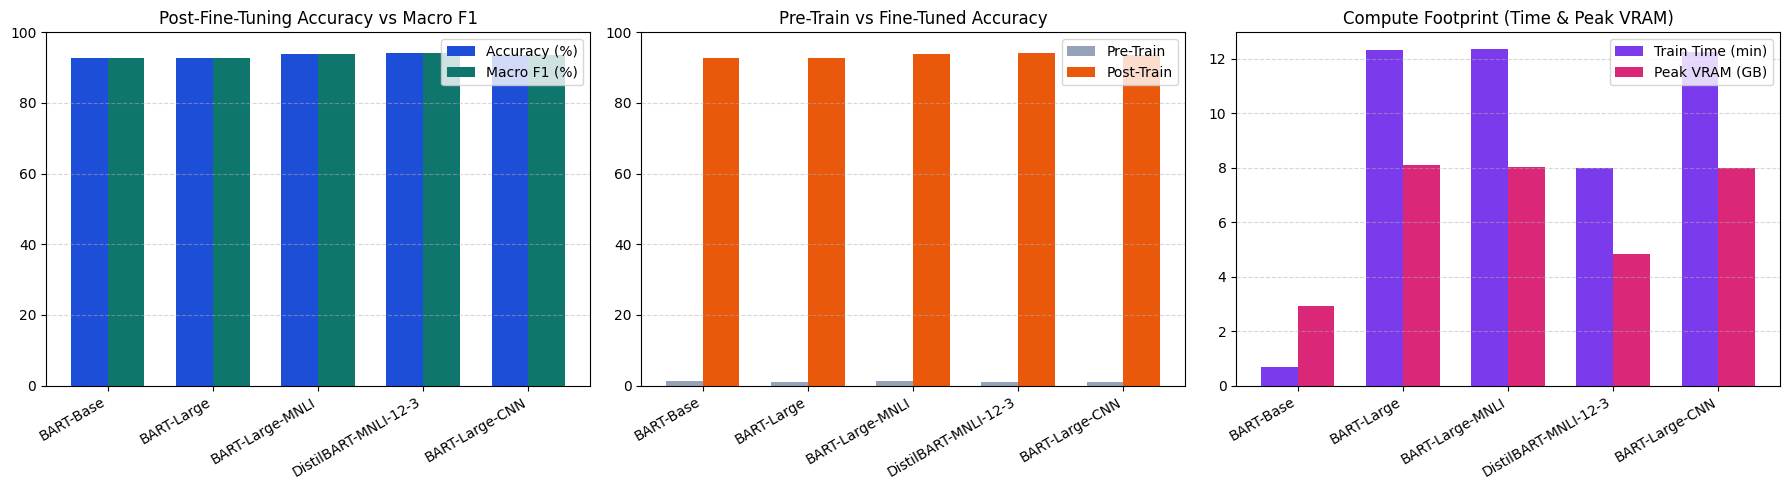

[SAVED] Chart saved to: /content/drive/MyDrive/NLP_Checkpoints/BART_training_Awais_Seed42/banking77_bart_comparison.png


In [8]:
# --- 8. Final Benchmark Summary Table & Comparison Charts ---
benchmark_df = pd.DataFrame(results_records)
print("=" * 95)
print(f"FINAL BANKING77 BART BENCHMARK SUMMARY (Train: {len(train_texts):,} | Test: {len(test_texts):,})")
print("=" * 95)

display_cols = [
    "Model Name", "Pre-Train Accuracy (%)", "Post-Train Accuracy (%)", "Accuracy Gain (%)",
    "Post-Train Macro F1 (%)", "Inference Latency (ms/query)",
    "Training Time (min)", "Peak VRAM Allocated (GB)", "Epochs"
]
print(benchmark_df[display_cols].to_markdown(index=False) if hasattr(benchmark_df, "to_markdown") else benchmark_df[display_cols])

plot_save_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bart_comparison.png")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = np.arange(len(benchmark_df))
w = 0.35

axes[0].bar(x - w/2, benchmark_df["Post-Train Accuracy (%)"], w, label="Accuracy (%)", color="#1d4ed8")
axes[0].bar(x + w/2, benchmark_df["Post-Train Macro F1 (%)"], w, label="Macro F1 (%)", color="#0f766e")
axes[0].set_title("Post-Fine-Tuning Accuracy vs Macro F1")
axes[0].set_xticks(x)
axes[0].set_xticklabels(benchmark_df["Model Name"], rotation=30, ha="right")
axes[0].set_ylim(0, 100)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].bar(x - w/2, benchmark_df["Pre-Train Accuracy (%)"], w, label="Pre-Train", color="#94a3b8")
axes[1].bar(x + w/2, benchmark_df["Post-Train Accuracy (%)"], w, label="Post-Train", color="#ea580c")
axes[1].set_title("Pre-Train vs Fine-Tuned Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(benchmark_df["Model Name"], rotation=30, ha="right")
axes[1].set_ylim(0, 100)
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

axes[2].bar(x - w/2, benchmark_df["Training Time (min)"], w, label="Train Time (min)", color="#7c3aed")
axes[2].bar(x + w/2, benchmark_df["Peak VRAM Allocated (GB)"], w, label="Peak VRAM (GB)", color="#db2777")
axes[2].set_title("Compute Footprint (Time & Peak VRAM)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(benchmark_df["Model Name"], rotation=30, ha="right")
axes[2].legend()
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(plot_save_path, dpi=200)
plt.show()
print(f"[SAVED] Chart saved to: {plot_save_path}")

In [9]:
# --- 9. Interactive Prediction Helper ---
def load_and_predict(query, model_save_name="BART-Base", top_k=3):
    model_dir = os.path.join(BASE_OUTPUT_DIR, model_save_name)
    if not os.path.exists(model_dir):
        print(f"[ERROR] Checkpoint '{model_dir}' not found.")
        return
    tok = AutoTokenizer.from_pretrained(model_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device)
    mdl.eval()
    enc = tok(query, return_tensors="pt", truncation=True, max_length=MAX_SEQ_LENGTH, padding=True)
    with torch.no_grad():
        out = mdl(input_ids=enc["input_ids"].to(device), attention_mask=enc["attention_mask"].to(device))
        probs = torch.softmax(extract_logits(out), dim=-1).squeeze(0)
        top_probs, top_ids = torch.topk(probs, k=top_k)
    print(f'Query: "{query}"')
    for rank, (idx_p, prob) in enumerate(zip(top_ids.tolist(), top_probs.tolist()), 1):
        print(f"   {rank}. {id2label[idx_p]:<45} ({prob*100:.2f}%)")
    del mdl, tok
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Example usage:
# load_and_predict("Can I transfer money directly using Apple Pay?", "BART-Base")